In [ ]:
!pip install librosa tensorflow scikit-learn matplotlib

In [2]:
from google.colab import files
uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [3]:
!pip install -q kaggle

!mkdir -p ~/.kaggle
!cp /content/kaggle.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

print("Kaggle API configured successfully!")

Kaggle API configured successfully!


In [4]:
!kaggle datasets download -d uwrfkaggler/ravdess-emotional-speech-audio

Dataset URL: https://www.kaggle.com/datasets/uwrfkaggler/ravdess-emotional-speech-audio
License(s): CC-BY-NC-SA-4.0
100% 429M/429M [00:02<00:00, 180MB/s]



In [5]:
import zipfile
import os

zip_path = "/content/ravdess-emotional-speech-audio.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/ravdess")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [6]:
import glob

audio_files = glob.glob(
    "/content/ravdess/**/*.wav",
    recursive=True
)

print("Total audio files:", len(audio_files))
print("First 5 audio files:")

for file in audio_files[:5]:
    print(file)

Total audio files: 2880
First 5 audio files:
/content/ravdess/Actor_07/03-01-06-02-01-01-07.wav
/content/ravdess/Actor_07/03-01-02-01-01-02-07.wav
/content/ravdess/Actor_07/03-01-02-01-02-01-07.wav
/content/ravdess/Actor_07/03-01-07-01-01-01-07.wav
/content/ravdess/Actor_07/03-01-05-01-02-02-07.wav


In [7]:
import glob
import os

audio_files = glob.glob(
    "/content/ravdess/**/*.wav",
    recursive=True
)

# Keep speech recordings only
speech_files = [
    f for f in audio_files
    if os.path.basename(f).split("-")[1] == "01"
]

print("Total audio files:", len(audio_files))
print("Speech audio files:", len(speech_files))

Total audio files: 2880
Speech audio files: 2880


In [8]:
import librosa
import numpy as np
import os

emotion_labels = {
    1: "neutral",
    2: "calm",
    3: "happy",
    4: "sad",
    5: "angry",
    6: "fearful",
    7: "disgust",
    8: "surprised"
}

X = []
y = []

for file in speech_files:

    filename = os.path.basename(file)
    parts = filename.split("-")

    emotion = int(parts[2])

    try:
        audio, sr = librosa.load(
            file,
            sr=22050,
            duration=3.5
        )

        mfcc = librosa.feature.mfcc(
            y=audio,
            sr=sr,
            n_mfcc=40,
            n_fft=2048,
            hop_length=512
        )

        target_frames = 151

        if mfcc.shape[1] < target_frames:
            mfcc = np.pad(
                mfcc,
                ((0, 0), (0, target_frames - mfcc.shape[1]))
            )
        else:
            mfcc = mfcc[:, :target_frames]

        X.append(mfcc)
        y.append(emotion - 1)

    except Exception as e:
        print("Error:", file, e)

X = np.array(X)
y = np.array(y)

print("MFCC features:", X.shape)
print("Emotion labels:", y.shape)
print("Feature extraction completed!")

MFCC features: (2880, 40, 151)
Emotion labels: (2880,)
Feature extraction completed!


In [9]:
speech_files = [
    f for f in audio_files
    if os.path.basename(f).split("-")[1] == "01"
]

print("Speech recordings:", len(speech_files))

Speech recordings: 2880


In [10]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten,
    Dense, Dropout, BatchNormalization
)
from tensorflow.keras.utils import to_categorical
import numpy as np

# Normalize features
X = X.astype("float32")
mean = X.mean()
std = X.std()
X = (X - mean) / (std + 1e-8)

# Reshape features
X = X[..., np.newaxis]

# Convert labels
y_cat = to_categorical(y, num_classes=8)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y_cat,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# CNN architecture
model = Sequential([
    Conv2D(32, (3, 3), activation="relu",
           input_shape=X_train.shape[1:]),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.4),
    Dense(8, activation="softmax")
])

# Compile model
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Train model
history = model.fit(
    X_train,
    y_train,
    epochs=25,
    batch_size=32,
    validation_split=0.2
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/25
58/58 ━━━━━━━━━━━━━━━━━━━━ 25s 371ms/step - accuracy: 0.1736 - loss: 3.5563 - val_accuracy: 0.1236 - val_loss: 2.1984
Epoch 2/25
58/58 ━━━━━━━━━━━━━━━━━━━━ 40s 370ms/step - accuracy: 0.2046 - loss: 1.9676 - val_accuracy: 0.1236 - val_loss: 5.0918
Epoch 3/25
58/58 ━━━━━━━━━━━━━━━━━━━━ 43s 399ms/step - accuracy: 0.2561 - loss: 1.8890 - val_accuracy: 0.1258 - val_loss: 5.5605
Epoch 4/25
58/58 ━━━━━━━━━━━━━━━━━━━━ 22s 373ms/step - accuracy: 0.2702 - loss: 1.8314 - val_accuracy: 0.1388 - val_loss: 5.0162
Epoch 5/25
58/58 ━━━━━━━━━━━━━━━━━━━━ 23s 400ms/step - accuracy: 0.3283 - loss: 1.7033 - val_accuracy: 0.1800 - val_loss: 4.0229
Epoch 6/25
58/58 ━━━━━━━━━━━━━━━━━━━━ 22s 384ms/step - accuracy: 0.3804 - loss: 1.5669 - val_accuracy: 0.1931 - val_loss: 2.9058
Epoch 7/25
58/58 ━━━━━━━━━━━━━━━━━━━━ 42s 402ms/step - accuracy: 0.4259 - loss: 1.4025 - val_accuracy: 0.2625 - val_loss: 2.1817
Epoch 8/25
58/58 ━━━━━━━━━━━━━━━━━━━━ 21s 359ms/step - accuracy: 0.4525 - loss: 1.3483 - val_accu

18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 121ms/step
Test Accuracy: 0.8246527777777778

Classification Report:
              precision    recall  f1-score   support

     neutral       0.83      0.63      0.72        38
        calm       0.80      0.91      0.85        76
       happy       0.70      0.90      0.79        77
         sad       0.75      0.75      0.75        77
       angry       0.86      0.86      0.86        77
     fearful       0.84      0.83      0.84        77
     disgust       0.95      0.79      0.87        77
   surprised       0.93      0.83      0.88        77

    accuracy                           0.82       576
   macro avg       0.83      0.81      0.82       576
weighted avg       0.83      0.82      0.83       576



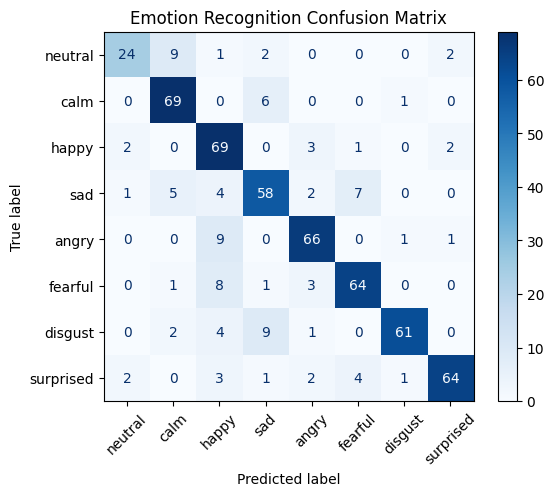

In [11]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import numpy as np
import matplotlib.pyplot as plt

# Predictions
y_pred = model.predict(X_test)

y_pred_labels = np.argmax(y_pred, axis=1)
y_true_labels = np.argmax(y_test, axis=1)

# Accuracy
print("Test Accuracy:",
      accuracy_score(y_true_labels, y_pred_labels))

# Classification report
print("\nClassification Report:")

print(classification_report(
    y_true_labels,
    y_pred_labels,
    target_names=[
        "neutral", "calm", "happy", "sad",
        "angry", "fearful", "disgust", "surprised"
    ]
))

# Confusion matrix
cm = confusion_matrix(y_true_labels, y_pred_labels)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "neutral", "calm", "happy", "sad",
        "angry", "fearful", "disgust", "surprised"
    ]
).plot(cmap="Blues", xticks_rotation=45)

plt.title("Emotion Recognition Confusion Matrix")
plt.show()

In [12]:
model.save("emotion_recognition_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [13]:
from google.colab import files

files.download("emotion_recognition_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>